In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Before Cleaning the Dataset

In [178]:
df = pd.read_csv("Netflix_Churn_Prediction.csv")
df.head(10)

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
0,NF100001,56,23,6.4,2,Premium,MOBILE,4,no
1,NF100002,69,15,46.0,26,Premium,Mobile,4,No
2,NF100003,46,33,49.9,25,Standard,Laptop,3,1
3,NF100004,32,25,37.9,2,Basic,Tablet,5,No
4,NF100005,60,17,73.7,12,Basic,Laptop,5,No
5,NF100006,25,33,25.0,8,Basic,Mobile,2,N
6,NF100007,38,47,12.7,9,standard,TV,1,N
7,NF100008,56 years,55,33.7,12,PREMIUM,Tablet,3,No
8,NF100009,36,2,7.5,26,Standard,Mobile,5,No
9,NF100010,40,14,46.6,9,Basic,Mobile,2,No


In [179]:
df.tail()

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
1195,NF101196,31,41,24.0,10,Premium,Laptop,1,No
1196,NF101197,49,54,57.1 hrs,25,Basic,Mobile,4,No
1197,NF101198,68,60 months,15.6,2,Standard,Phone,5,0
1198,NF100277,55,47,72.5,9,Basic,NaN,3,No
1199,NF101200,50,14,48.5,11,Standard,Mobile,1,No


In [180]:
df.shape

(1200, 9)

In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer_ID         1200 non-null   object
 1   Age                 1154 non-null   object
 2   Tenure_Months       1149 non-null   object
 3   Watch_Hours         1134 non-null   object
 4   Login_Frequency     1145 non-null   object
 5   Plan                1159 non-null   object
 6   Device              1153 non-null   object
 7   Satisfaction_Score  1142 non-null   object
 8   Churn               1175 non-null   object
dtypes: object(9)
memory usage: 84.5+ KB


In [182]:
df.describe()

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
count,1200,1154,1149,1134,1145,1159,1153,1142,1175
unique,1156,96,99,662,60,18,18,20,12
top,NF100065,43,29,17.4,23,Standard,Laptop,1,No
freq,3,30,29,8,52,328,219,248,783


In [183]:
df.columns.tolist()

['Customer_ID',
 'Age',
 'Tenure_Months',
 'Watch_Hours',
 'Login_Frequency',
 'Plan',
 'Device',
 'Satisfaction_Score',
 'Churn']

In [184]:
df.dtypes

Customer_ID           object
Age                   object
Tenure_Months         object
Watch_Hours           object
Login_Frequency       object
Plan                  object
Device                object
Satisfaction_Score    object
Churn                 object
dtype: object

In [185]:
df.isnull().sum()

Customer_ID            0
Age                   46
Tenure_Months         51
Watch_Hours           66
Login_Frequency       55
Plan                  41
Device                47
Satisfaction_Score    58
Churn                 25
dtype: int64

In [186]:
(df.isnull().sum()/len(df)*100).round(2)

Customer_ID           0.00
Age                   3.83
Tenure_Months         4.25
Watch_Hours           5.50
Login_Frequency       4.58
Plan                  3.42
Device                3.92
Satisfaction_Score    4.83
Churn                 2.08
dtype: float64

In [187]:
df.duplicated().sum()


24

In [188]:
# Display duplicate rows before removal
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate rows:", df.duplicated().sum())

duplicates.sort_values(by="Customer_ID")

Total duplicate rows: 24


,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
64,NF100065,64,47,35.5,NaN,Basic,Laptop,1,No
1170,NF100065,64,47,35.5,NaN,Basic,Laptop,1,No
84,NF100085,48,6,61.2,16,Basic,Tablet,2,NaN
1162,NF100085,48,6,61.2,16,Basic,Tablet,2,NaN
87,NF100088,25,NaN,22.9,23,standard,Laptop,1,No
1169,NF100088,25,NaN,22.9,23,standard,Laptop,1,No
330,NF100331,42,52,38.9,20,Standard,TV,2,No
1163,NF100331,42,52,38.9,20,Standard,TV,2,No
355,NF100356,39,54,70.9h,21,Basic,Mobile,3,Active
1173,NF100356,39,54,70.9h,21,Basic,Mobile,3,Active


In [189]:
df[df.duplicated()]

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
1150,NF100959,46,53,19.2 hours,20,Basic,Laptop,3,No
1151,NF100503,18,8,25.5,23,Basic,TABLET,5,No
1152,NF100402,40,17,25.7,7,Basic,TV,5,Yes
1153,NF101143,19,37 months,27.1,29,Premium,Mobile,4,No
1154,NF100679,59,5,87.5,18,Basic,TV,1,No
1155,NF100998,52,38 months,17.4,20,Basic,Mobile,2,No
1156,NF100684,52,9,NaN,28,Standard,Laptop,1,No
1157,NF100617,27,49,49.8,8,Basic,TV,5,0
1158,NF100964,38,20,17.4,28,Standard,TV,1,N
1159,NF100360,55,4,47.1,17,Standard,TV,5,No


In [190]:
df = df.drop_duplicates()

In [191]:
df.duplicated().sum()

0

In [192]:
df.shape

(1176, 9)

# Cleaning Customer_ID column

In [193]:
df["Customer_ID"].duplicated().sum()

20

In [194]:
df["Customer_ID"].isnull().sum()

0

In [195]:
df[df["Customer_ID"].duplicated(keep=False)].sort_values("Customer_ID")

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
64,NF100065,64,47,35.5,NaN,Basic,Laptop,1,No
1180,NF100065,54,8,56.7,30,Standard,Mobile,1,No
100,NF100101,62,60,28.3,5,Standard,Laptop,1,Yes
1112,NF100101,43,51,83.8,18,STANDARD,Laptop,4,0
169,NF100170,40,59,17.3,NaN,Basic,tv,3,no
865,NF100170,26 years,36,37.8,9,Standard,Mobile,1,No
174,NF100175,46 years,7,45.3,3,BASIC,Laptop,1,No
304,NF100175,22,36,28.8,1,Basic,Tablet,4,NO
204,NF100268,56,30,43.7,19,NaN,TV,5,No
267,NF100268,20,NaN,45.3,5,Standard,Tablet,2,No


# Cleaning Age column

In [196]:
df["Age"].unique()

array(['56', '69', '46', '32', '60', '25', '38', '56 years', '36', '40',
       '28', '41', '70', '53', '57', '20', nan, '19', '61', '47', '55',
       '50', '29', '39', '42', '66', '44', '59', '45', '33', '-5', '64',
       '68', '54', '24', '26', '35', '21', '31', '67', '43', '37', '52',
       '34', '23', '51', '27', '48', '65', '62', '58', '18', '22', ' 64 ',
       '30', '49', '46 years', '61yr', '56yr', ' 44 ', ' 19 ', ' 28 ',
       ' 58 ', ' 50 ', 'unknown', '150', '57 years', ' 46 ', '63', '21yr',
       '0', '70yr', '43yr', '49 years', '33yr', '45yr', '34 years',
       '66yr', '70 years', '44yr', '62 years', ' 48 ', ' 56 ', '36yr',
       '50 years', '66 years', '26 years', '37 years', '30yr', '68 years',
       '22yr', '39yr', '34yr', ' 54 ', ' 29 ', ' 22 ', ' 43 '],
      dtype=object)

In [197]:
df["Age"].nunique()

96

In [198]:
df["Age"].value_counts()

Age
43          30
50          29
45          27
42          26
18          26
            ..
43yr         1
49 years     1
33yr         1
45yr         1
 43          1
Name: count, Length: 96, dtype: int64

In [199]:
# cleaning Age column

df["Age"] = df["Age"].str.extract(r'(\d+)', expand = False)

In [200]:
df["Age"].nunique()

56

In [201]:
df["Age"].unique()

array(['56', '69', '46', '32', '60', '25', '38', '36', '40', '28', '41',
       '70', '53', '57', '20', nan, '19', '61', '47', '55', '50', '29',
       '39', '42', '66', '44', '59', '45', '33', '5', '64', '68', '54',
       '24', '26', '35', '21', '31', '67', '43', '37', '52', '34', '23',
       '51', '27', '48', '65', '62', '58', '18', '22', '30', '49', '150',
       '63', '0'], dtype=object)

In [202]:
df["Age"].value_counts()

Age
43     32
50     31
45     28
54     27
66     27
68     27
42     26
52     26
18     26
56     25
62     25
19     25
64     25
22     25
49     25
70     24
41     24
23     23
25     23
20     23
53     22
69     22
47     22
40     22
31     22
34     22
61     21
65     21
29     20
28     20
36     20
39     19
57     19
26     19
21     19
30     19
37     19
46     18
27     17
51     17
33     17
35     17
55     17
38     17
67     16
59     16
48     15
58     15
32     15
24     14
44     14
63     13
60     12
150     4
5       3
0       3
Name: count, dtype: int64

In [203]:
df["Age"] = df["Age"].astype(float)

In [204]:
df.dtypes

Customer_ID            object
Age                   float64
Tenure_Months          object
Watch_Hours            object
Login_Frequency        object
Plan                   object
Device                 object
Satisfaction_Score     object
Churn                  object
dtype: object

In [205]:
df["Age"].isnull().sum()

51

In [206]:
df.isnull().sum()

Customer_ID            0
Age                   51
Tenure_Months         50
Watch_Hours           64
Login_Frequency       53
Plan                  41
Device                46
Satisfaction_Score    57
Churn                 24
dtype: int64

In [207]:
df.select_dtypes(include = "number").columns.tolist()

['Age']

In [208]:
# filling Age column's null values using MEDIAN ......... it is right skewed

df["Age"].fillna(df["Age"].median(),inplace = True)

In [209]:
df.isnull().sum()

Customer_ID            0
Age                    0
Tenure_Months         50
Watch_Hours           64
Login_Frequency       53
Plan                  41
Device                46
Satisfaction_Score    57
Churn                 24
dtype: int64

In [210]:
df["Age"].value_counts()

Age
44.0     65
43.0     32
50.0     31
45.0     28
54.0     27
68.0     27
66.0     27
42.0     26
18.0     26
52.0     26
62.0     25
19.0     25
49.0     25
64.0     25
22.0     25
56.0     25
41.0     24
70.0     24
20.0     23
23.0     23
25.0     23
31.0     22
53.0     22
69.0     22
34.0     22
47.0     22
40.0     22
65.0     21
61.0     21
36.0     20
28.0     20
29.0     20
30.0     19
39.0     19
26.0     19
21.0     19
57.0     19
37.0     19
46.0     18
51.0     17
27.0     17
33.0     17
35.0     17
55.0     17
38.0     17
67.0     16
59.0     16
48.0     15
58.0     15
32.0     15
24.0     14
63.0     13
60.0     12
150.0     4
5.0       3
0.0       3
Name: count, dtype: int64

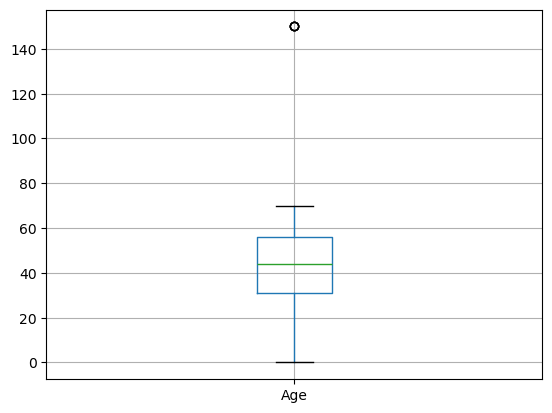

In [211]:
df.boxplot(column="Age")
plt.show()

In [212]:
df["Age"].skew()

0.7673183046740013

### there is invalid ages in age column ------> invalid ages like 0 and 150

In [213]:
# replacing them in NaN and after that fill them by median

df.loc[(df["Age"] <= 0) | (df["Age"] > 100), "Age"] = np.nan

In [214]:
df["Age"].value_counts()

Age
44.0    65
43.0    32
50.0    31
45.0    28
54.0    27
68.0    27
66.0    27
42.0    26
18.0    26
52.0    26
62.0    25
19.0    25
49.0    25
64.0    25
22.0    25
56.0    25
41.0    24
70.0    24
23.0    23
20.0    23
25.0    23
47.0    22
40.0    22
34.0    22
31.0    22
53.0    22
69.0    22
61.0    21
65.0    21
36.0    20
29.0    20
28.0    20
57.0    19
30.0    19
26.0    19
21.0    19
39.0    19
37.0    19
46.0    18
27.0    17
51.0    17
33.0    17
35.0    17
55.0    17
38.0    17
67.0    16
59.0    16
48.0    15
58.0    15
32.0    15
24.0    14
63.0    13
60.0    12
5.0      3
Name: count, dtype: int64

In [215]:
df["Age"].count()

1169

In [216]:
df["Age"]=df["Age"].fillna(df["Age"].median())

In [217]:
df["Age"].isnull().sum()

0

In [218]:
df["Age"].describe()

count    1176.000000
mean       44.014456
std        15.160272
min         5.000000
25%        31.000000
50%        44.000000
75%        56.000000
max        70.000000
Name: Age, dtype: float64

In [219]:
df["Age"].skew()

-0.05098737229860548

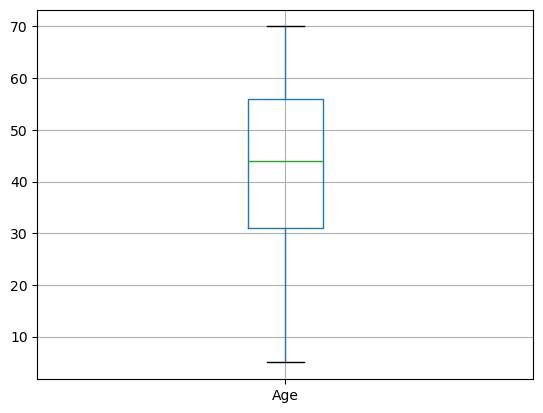

In [220]:
df.boxplot(column="Age")
plt.show()

# Cleaning Tenure_Months Column

In [221]:
# cleaning of column Tenure month

df["Tenure_Months"].isnull().sum()

50

In [222]:
df["Tenure_Months"].unique()

array(['23', '15', '33', '25', '17', '47', '55', '2', '14', '53', '40m',
       '40', '51', '39', nan, '6', '3', '7', '8', '42', '52', '29', '30',
       '27', '36', '38', '57', '37m', '4', '22', '10', '5', '59', '54',
       '13', '31', '45', '24', '56', '12m', '26', '43', '20', '11',
       '40 months', '46', '12', ' 40 ', '60', '44', '48', '37',
       '49 months', '150', '58', '9', '41', '21', '1', '35', '18',
       '34 months', '49', ' 22 ', '28', '50', '32', '19', '16', '1m',
       '34', '999', '54 months', '0', '30m', ' 32 ', ' 2 ', ' 29 ',
       ' 58 ', '42m', '25 months', '-2', '15 months', '17m', ' 23 ',
       '35m', '4 months', '15m', ' 48 ', '59 months', '29m', '20m',
       '46 months', ' 11 ', '38 months', '28 months', '37 months', ' 21 ',
       '14m', '60 months'], dtype=object)

In [223]:
df["Tenure_Months"].nunique()

99

In [224]:
df["Tenure_Months"] = df["Tenure_Months"].str.extract(r'(\d+)',expand = False) 

In [225]:
df["Tenure_Months"].unique()

array(['23', '15', '33', '25', '17', '47', '55', '2', '14', '53', '40',
       '51', '39', nan, '6', '3', '7', '8', '42', '52', '29', '30', '27',
       '36', '38', '57', '37', '4', '22', '10', '5', '59', '54', '13',
       '31', '45', '24', '56', '12', '26', '43', '20', '11', '46', '60',
       '44', '48', '49', '150', '58', '9', '41', '21', '1', '35', '18',
       '34', '28', '50', '32', '19', '16', '999', '0'], dtype=object)

In [226]:
df["Tenure_Months"].nunique()

63

In [227]:
df["Tenure_Months"].value_counts()

Tenure_Months
29     31
59     26
17     25
32     24
51     23
       ..
48      9
16      9
150     5
0       5
999     1
Name: count, Length: 63, dtype: int64

In [228]:
df["Tenure_Months"]= df["Tenure_Months"].astype(float)

In [229]:
df.dtypes

Customer_ID            object
Age                   float64
Tenure_Months         float64
Watch_Hours            object
Login_Frequency        object
Plan                   object
Device                 object
Satisfaction_Score     object
Churn                  object
dtype: object

In [230]:
df.select_dtypes(include = "number").columns.tolist()

['Age', 'Tenure_Months']

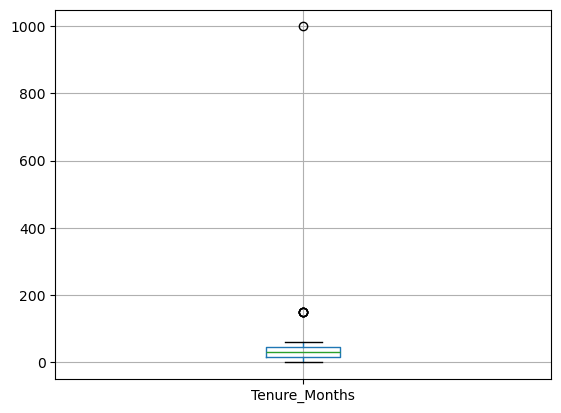

In [231]:
df.boxplot(column="Tenure_Months")
plt.show()

In [232]:
df["Tenure_Months"].skew()

19.765442382179128

In [233]:
# detecting outlier

Q1 = df["Tenure_Months"].quantile(0.25)
Q3 = df["Tenure_Months"].quantile(0.75)

IQR = Q3-Q1

lower_whisker = Q1-1.5*IQR
upper_whisker = Q3+1.5*IQR

print("Q1",Q1)
print("Q3",Q3)
print("IQR",IQR)
print("lower_whisker",lower_whisker)
print("upper_whisker",upper_whisker)


Q1 16.0
Q3 45.0
IQR 29.0
lower_whisker -27.5
upper_whisker 88.5


### insights
- as Tenure_Months column contain 150 and 999 outlier.
- by doing detecting outlier and finding out lowerWhisker and UpperWhisker are -27,88.5.
- this column having max month is 60
- so we can't do capping bcz -27 not valid and 88.5 is maximum as compared to month 60. so it can be make an again outlier for it
- we need to replace 150,999 with NaN and fill them using median.

In [234]:
df.loc[(df["Tenure_Months"]>60) ,"Tenure_Months"] = np.nan 

In [235]:
df["Tenure_Months"].unique()

array([23., 15., 33., 25., 17., 47., 55.,  2., 14., 53., 40., 51., 39.,
       nan,  6.,  3.,  7.,  8., 42., 52., 29., 30., 27., 36., 38., 57.,
       37.,  4., 22., 10.,  5., 59., 54., 13., 31., 45., 24., 56., 12.,
       26., 43., 20., 11., 46., 60., 44., 48., 49., 58.,  9., 41., 21.,
        1., 35., 18., 34., 28., 50., 32., 19., 16.,  0.])

In [236]:
df["Tenure_Months"].isnull().sum()

56

In [237]:
df["Tenure_Months"] = df["Tenure_Months"].fillna(df["Tenure_Months"].median())

In [238]:
df["Tenure_Months"].isnull().sum()

0

In [239]:
df.dtypes

Customer_ID            object
Age                   float64
Tenure_Months         float64
Watch_Hours            object
Login_Frequency        object
Plan                   object
Device                 object
Satisfaction_Score     object
Churn                  object
dtype: object

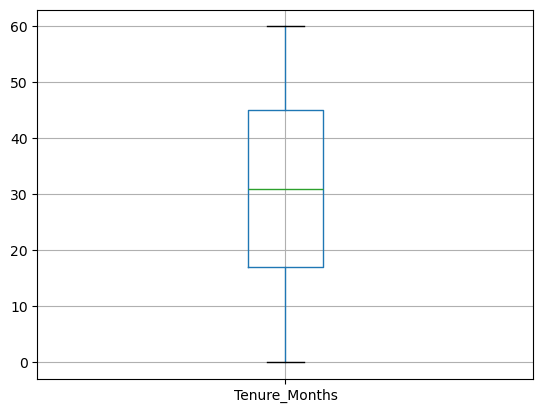

In [240]:
df.boxplot(column="Tenure_Months")
plt.show()

# Cleaning Watch_Hours Column

In [241]:
df["Watch_Hours"].head()

0       6.4
1      46.0
2     49.9 
3      37.9
4      73.7
Name: Watch_Hours, dtype: object

In [242]:
df["Watch_Hours"].tail()

1195        24.0
1196    57.1 hrs
1197        15.6
1198        72.5
1199        48.5
Name: Watch_Hours, dtype: object

In [243]:
df.dtypes

Customer_ID            object
Age                   float64
Tenure_Months         float64
Watch_Hours            object
Login_Frequency        object
Plan                   object
Device                 object
Satisfaction_Score     object
Churn                  object
dtype: object

In [244]:
df["Watch_Hours"].dtype

dtype('O')

In [245]:
df["Watch_Hours"].unique()

array(['6.4', '46.0', ' 49.9 ', '37.9', '73.7', '25.0', '12.7', '33.7',
       '7.5', '46.6', '58.1', '14.7', '64.5', nan, '49.6', '81.0', '500',
       '28.0', '36.9', '19.6', '27.2', '40.2', '43.5', '52.1', '163.7',
       '21.1', '57.9h', '47.2', '26.1', '55.0', '21.5h', '39.2',
       '111.9 hrs', '30.0', '41.7', '19.0', '47.7', '70.0', '34.1',
       '55.5', '49.4', '71.5', '55.6', '80.6 hrs', '33.9', '16.2', '11.7',
       '33.0', '44.3', '25.2h', '6.3', '25.5', '29.9', '39.5', '86.9',
       '9.9', '59.1', '55.8', '50.4', '35.5', '55.1', '22.2', '20.4',
       '9.1', '50.5', '27.0', '20.6', '44.1', '9999', '84.9', '38.2',
       '52.7', '33.4', '50.7', '75.3', '33.1', '61.2', '25.2', '103.2',
       '22.9', '122.9', '16.7', '31.9', '52.2', '78.1', '87.5', '51.0',
       '23.9', '69.0', '47.9', '28.3', '24.1', '40.8', '70.9', '42.7',
       '59.6', '109.1', '42.4', '20.3', '57.5', '92.7', '32.9', '-10',
       ' 62.3 ', '24.3', '45.8', '0', '21.9 hrs', '42.2', '60.0', '119.4',
  

In [246]:
df["Watch_Hours"].nunique()

662

In [247]:
df["Watch_Hours"].isnull().sum()

64

In [248]:
df["Watch_Hours"].value_counts()

Watch_Hours
33.1          7
17.4          6
46.9          6
25.0          6
55.6          5
             ..
46.0          1
106.5         1
73.8 hours    1
20.7          1
57.1 hrs      1
Name: count, Length: 662, dtype: int64

In [249]:
# CLeaning values like 73.8 hours ---> 73.8


df["Watch_Hours"] = df["Watch_Hours"].str.extract(r"(\d+\.?\d*)", expand=False)



In [250]:
df["Watch_Hours"].unique()

array(['6.4', '46.0', '49.9', '37.9', '73.7', '25.0', '12.7', '33.7',
       '7.5', '46.6', '58.1', '14.7', '64.5', nan, '49.6', '81.0', '500',
       '28.0', '36.9', '19.6', '27.2', '40.2', '43.5', '52.1', '163.7',
       '21.1', '57.9', '47.2', '26.1', '55.0', '21.5', '39.2', '111.9',
       '30.0', '41.7', '19.0', '47.7', '70.0', '34.1', '55.5', '49.4',
       '71.5', '55.6', '80.6', '33.9', '16.2', '11.7', '33.0', '44.3',
       '25.2', '6.3', '25.5', '29.9', '39.5', '86.9', '9.9', '59.1',
       '55.8', '50.4', '35.5', '55.1', '22.2', '20.4', '9.1', '50.5',
       '27.0', '20.6', '44.1', '9999', '84.9', '38.2', '52.7', '33.4',
       '50.7', '75.3', '33.1', '61.2', '103.2', '22.9', '122.9', '16.7',
       '31.9', '52.2', '78.1', '87.5', '51.0', '23.9', '69.0', '47.9',
       '28.3', '24.1', '40.8', '70.9', '42.7', '59.6', '109.1', '42.4',
       '20.3', '57.5', '92.7', '32.9', '10', '62.3', '24.3', '45.8', '0',
       '21.9', '42.2', '60.0', '119.4', '18.2', '46.5', '40.0', '56.6'

In [251]:
df["Watch_Hours"].nunique()

606

In [252]:
df["Watch_Hours"] = df["Watch_Hours"].astype(float)

In [253]:
df["Watch_Hours"].dtype

dtype('float64')

In [254]:
df.select_dtypes(include='number').columns.tolist()

['Age', 'Tenure_Months', 'Watch_Hours']

In [255]:
df["Watch_Hours"].isnull().sum()

69

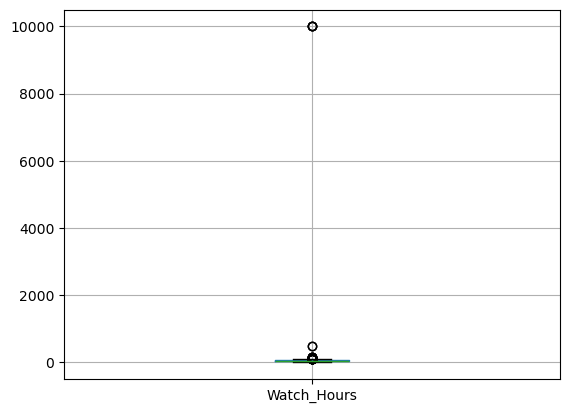

In [256]:
df.boxplot("Watch_Hours")
plt.show()

In [257]:
df["Watch_Hours"].skew()

16.497307898779635

In [258]:
df.loc[df["Watch_Hours"].isin([9999,500]), "Watch_Hours"] = np.nan

In [259]:
df["Watch_Hours"].isnull().sum()

75

In [260]:
df["Watch_Hours"].isin([500.9999]).sum()

0

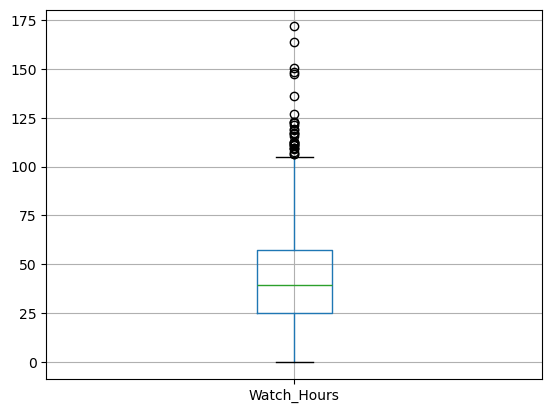

In [261]:
df.boxplot("Watch_Hours")
plt.show()

In [262]:
# checking IQR

Q1 = df["Watch_Hours"].quantile(0.25)
Q3 = df["Watch_Hours"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*IQR
upper = Q3+1.5*IQR

print("lower:",lower)
print("upper:",upper)

lower: -22.900000000000006
upper: 105.9


In [263]:
# checked is negative value present 
(df["Watch_Hours"] < 0).sum()

0

In [264]:
# checked is there have any value above upper_whisker
(df["Watch_Hours"] > 105.9).sum()

30

In [265]:
# capping
df["Watch_Hours"] = np.where(df["Watch_Hours"]>upper, upper, df["Watch_Hours"])

In [266]:
(df["Watch_Hours"] > 105.9).sum()

0

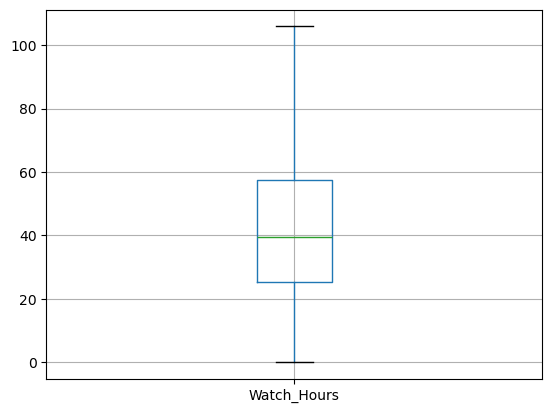

In [267]:
df.boxplot("Watch_Hours")
plt.show()

In [268]:
df["Watch_Hours"].skew()

0.7540218114904594

In [269]:
df["Watch_Hours"].isnull().sum()

75

In [270]:
df["Watch_Hours"] = df["Watch_Hours"].fillna(df["Watch_Hours"].median())

In [271]:
df["Watch_Hours"].isnull().sum()

0

In [272]:
df["Watch_Hours"].skew()

0.8105302251090892

# Cleaning Login_Frequency Column

In [273]:
df["Login_Frequency"].unique()

array(['2', '26', '25', '12', '8', '9', '10', ' 16 ', '0', '7', '28', '1',
       '19', '4', '24', '22', ' 27 ', '14', '29', '15', '5', '20', '21',
       nan, ' 26 ', '6', '13', '16', '18', '3', '23', '200', '27', '17',
       ' 13 ', '11', '30', ' 29 ', ' 8 ', '999', ' 22 ', '21 times',
       '26 times', ' 11 ', '2 times', '6 times', ' 21 ', ' 24 ', '-3',
       '30 times', '19 times', ' 2 ', ' 6 ', ' 1 ', ' 19 ', '3 times',
       ' 17 ', '23 times', '14 times', '18 times', '8 times'],
      dtype=object)

In [274]:
df["Login_Frequency"].isnull().sum()

53

In [275]:
df["Login_Frequency"] = df["Login_Frequency"].str.extract(r'(\d+)',expand = False)

In [276]:
df["Login_Frequency"].unique()

array(['2', '26', '25', '12', '8', '9', '10', '16', '0', '7', '28', '1',
       '19', '4', '24', '22', '27', '14', '29', '15', '5', '20', '21',
       nan, '6', '13', '18', '3', '23', '200', '17', '11', '30', '999'],
      dtype=object)

In [277]:
df["Login_Frequency"] = df["Login_Frequency"].astype(float)

In [278]:
df["Login_Frequency"].dtype

dtype('float64')

In [279]:
df.select_dtypes(include = "number").columns.tolist()

['Age', 'Tenure_Months', 'Watch_Hours', 'Login_Frequency']

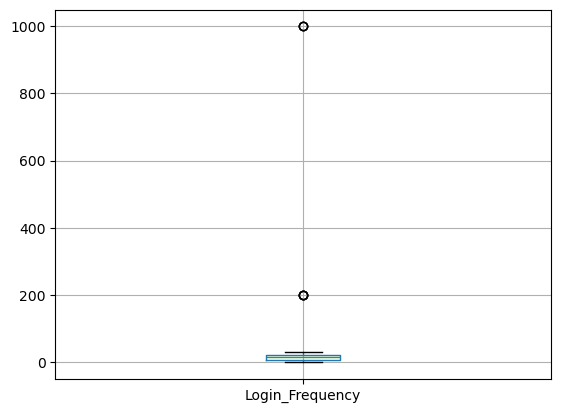

In [280]:
df.boxplot("Login_Frequency")
plt.show()

In [281]:
df["Login_Frequency"].describe()

count    1123.000000
mean       19.036509
std        52.611866
min         0.000000
25%         8.000000
50%        16.000000
75%        23.000000
max       999.000000
Name: Login_Frequency, dtype: float64

In [282]:
# checking and finding lower-upper whisker

Q1 = df["Login_Frequency"].quantile(0.25)
Q3 = df["Login_Frequency"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR


print("Lower:", lower)
print("Upper:", upper)

Lower: -14.5
Upper: 45.5


In [283]:
df["Login_Frequency"].isin([999,200]).sum()

7

In [284]:
df.loc[df["Login_Frequency"]>50,"Login_Frequency"]=np.nan

In [285]:
df["Login_Frequency"].isin([999,200]).sum()

0

In [286]:
df["Login_Frequency"].unique()

array([ 2., 26., 25., 12.,  8.,  9., 10., 16.,  0.,  7., 28.,  1., 19.,
        4., 24., 22., 27., 14., 29., 15.,  5., 20., 21., nan,  6., 13.,
       18.,  3., 23., 17., 11., 30.])

In [287]:
df["Login_Frequency"].isnull().sum()

60

In [288]:
df["Login_Frequency"] = df["Login_Frequency"].fillna(df["Login_Frequency"].median())

In [289]:
df["Login_Frequency"].isnull().sum()

0

In [290]:
df["Login_Frequency"].skew()

-0.06328730621990428

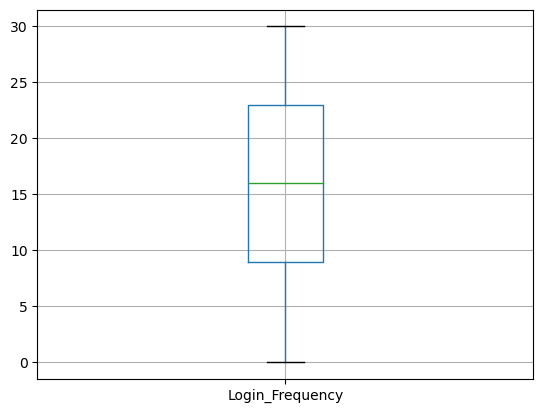

In [291]:
df.boxplot("Login_Frequency")
plt.show()

In [292]:
df.select_dtypes(include="number").columns.tolist()

['Age', 'Tenure_Months', 'Watch_Hours', 'Login_Frequency']

In [293]:
df.dtypes

Customer_ID            object
Age                   float64
Tenure_Months         float64
Watch_Hours           float64
Login_Frequency       float64
Plan                   object
Device                 object
Satisfaction_Score     object
Churn                  object
dtype: object

# Cleaning Plan Column

In [294]:
df["Plan"].unique()

array(['Premium', 'Standard ', 'Basic', 'standard', ' PREMIUM',
       'Standard', nan, 'PREMIUM', 'basic plan', 'STANDARD', ' BASIC',
       'BASIC', 'Basic ', 'basic', 'Premium ', 'premium plan', 'premium',
       ' STANDARD', 'standard plan'], dtype=object)

In [295]:
# removing extra spaces

df["Plan"] = df["Plan"].str.strip()

In [296]:
df["Plan"].unique()

array(['Premium', 'Standard', 'Basic', 'standard', 'PREMIUM', nan,
       'basic plan', 'STANDARD', 'BASIC', 'basic', 'premium plan',
       'premium', 'standard plan'], dtype=object)

In [297]:
# converting to lowercase

df["Plan"] = df["Plan"].str.lower()

In [298]:
df["Plan"].unique()

array(['premium', 'standard', 'basic', nan, 'basic plan', 'premium plan',
       'standard plan'], dtype=object)

In [299]:
# replacing "basic plan" ----> "basic"

df["Plan"] = df["Plan"].str.replace("plan","")

In [300]:
df["Plan"].unique()

array(['premium', 'standard', 'basic', nan, 'basic ', 'premium ',
       'standard '], dtype=object)

In [301]:
# convert it in title format

df["Plan"] = df["Plan"].str.title()

In [302]:
df["Plan"].unique()

array(['Premium', 'Standard', 'Basic', nan, 'Basic ', 'Premium ',
       'Standard '], dtype=object)

In [303]:
df["Plan"] = df["Plan"].str.strip()

In [304]:
df['Plan'].unique()

array(['Premium', 'Standard', 'Basic', nan], dtype=object)

In [305]:
df["Plan"].isnull().sum()

41

In [306]:
# this column is categorical so we will fill null values with mode

df["Plan"] = df["Plan"].fillna(df["Plan"].mode()[0])

In [307]:
df["Plan"].isnull().sum()

0

In [308]:
df["Plan"].value_counts()

Plan
Standard    475
Basic       422
Premium     279
Name: count, dtype: int64

# Cleaning of Device Column

In [309]:
df["Device"].unique()

array([' MOBILE', 'Mobile', 'Laptop', 'Tablet', ' TV', nan, 'mobile',
       ' TABLET', 'Tv', 'laptop', 'Tab', 'TV', 'tablet', 'Smart TV', 'tv',
       'Laptop ', ' LAPTOP', 'Phone', 'Mobile '], dtype=object)

In [310]:
# removing extra spaces

df["Device"] = df["Device"].str.strip()

In [311]:
df["Device"].unique()

array(['MOBILE', 'Mobile', 'Laptop', 'Tablet', 'TV', nan, 'mobile',
       'TABLET', 'Tv', 'laptop', 'Tab', 'tablet', 'Smart TV', 'tv',
       'LAPTOP', 'Phone'], dtype=object)

In [312]:
# converting to lower

df["Device"] = df["Device"].str.lower()

In [313]:
# replacing values to its original naming

df["Device"] = df["Device"].replace(
    {
        "mobile":"Mobile",
        "phone":"Mobile",
        "laptop":"Laptop",
        "tab":"Tablet",
        "tablet":"Tablet",
        "smart tv":"TV",
        "tv":"TV"
    }
)


In [314]:
df["Device"].unique()

array(['Mobile', 'Laptop', 'Tablet', 'TV', nan], dtype=object)

In [315]:
df["Device"].isna().sum()

46

In [316]:
df["Device"] = df["Device"].fillna(df["Device"].mode()[0])

In [317]:
df["Device"].isna().sum()

0

In [318]:
df["Device"].value_counts()

Device
Tablet    341
Laptop    287
TV        283
Mobile    265
Name: count, dtype: int64

In [319]:
df["Device"].nunique()

4

# Cleaning of Satisfaction_Score column

In [320]:
df["Satisfaction_Score"].unique()

array(['4', '3', '5', '2', '1', nan, '2/5', ' 5 ', ' 3 ', ' 4 ', ' 1 ',
       '6', '4/5', '5/5', 'unknown', ' 2 ', '99', '1/5', '3/5', '0', '10'],
      dtype=object)

In [321]:
df["Satisfaction_Score"] = df["Satisfaction_Score"].str.strip()

In [322]:
df["Satisfaction_Score"].unique()

array(['4', '3', '5', '2', '1', nan, '2/5', '6', '4/5', '5/5', 'unknown',
       '99', '1/5', '3/5', '0', '10'], dtype=object)

In [323]:
df["Satisfaction_Score"] = df["Satisfaction_Score"].str.extract(r"(\d+)",expand = False)

In [324]:
df["Satisfaction_Score"].unique()

array(['4', '3', '5', '2', '1', nan, '6', '99', '0', '10'], dtype=object)

In [325]:
df["Satisfaction_Score"] = df["Satisfaction_Score"].astype(float)

In [326]:
df["Satisfaction_Score"].unique()

array([ 4.,  3.,  5.,  2.,  1., nan,  6., 99.,  0., 10.])

In [327]:
# satisfaction score must be 1-5.....so,excluding 1-5 all are invalid score. replacing them with nan

df.loc[(df["Satisfaction_Score"]<1) | (df["Satisfaction_Score"]>5), "Satisfaction_Score"] = np.nan

In [328]:
df["Satisfaction_Score"].unique()

array([ 4.,  3.,  5.,  2.,  1., nan])

In [329]:
df["Satisfaction_Score"].isnull().sum()

72

In [330]:
df["Satisfaction_Score"] = df["Satisfaction_Score"].fillna(df["Satisfaction_Score"].median())

In [331]:
df["Satisfaction_Score"].isnull().sum()

0

In [332]:
df["Satisfaction_Score"].unique()

array([4., 3., 5., 2., 1.])

# Cleaning Churn Column

In [333]:
df["Churn"].unique()

array(['no', 'No', '1', 'N', 'Yes', ' NO', 'Churned', '0', nan, ' YES',
       'Active', 'Y', 'yes'], dtype=object)

In [334]:
df["Churn"] = df["Churn"].str.strip()

df["Churn"].unique()

array(['no', 'No', '1', 'N', 'Yes', 'NO', 'Churned', '0', nan, 'YES',
       'Active', 'Y', 'yes'], dtype=object)

In [335]:
df["Churn"] = df["Churn"].str.lower()

df["Churn"].unique()

array(['no', '1', 'n', 'yes', 'churned', '0', nan, 'active', 'y'],
      dtype=object)

In [336]:
df["Churn"] = df["Churn"].replace(
    {
        "yes":"Yes",
        "1":"Yes",
        "y":"Yes",
        "churned":"Yes",
        "no":"No",
        "n":"No",
        "active":"No",
        "0":"No"
        
    }
)

In [337]:
df["Churn"].value_counts(dropna=False)

Churn
No     977
Yes    175
NaN     24
Name: count, dtype: int64

In [338]:
df["Churn"].unique()

array(['No', 'Yes', nan], dtype=object)

# After Cleaning the Dataset

In [339]:
df.head(20)

,Customer_ID,Age,Tenure_Months,Watch_Hours,Login_Frequency,Plan,Device,Satisfaction_Score,Churn
0,NF100001,56.0,23.0,6.4,2.0,Premium,Mobile,4.0,No
1,NF100002,69.0,15.0,46.0,26.0,Premium,Mobile,4.0,No
2,NF100003,46.0,33.0,49.9,25.0,Standard,Laptop,3.0,Yes
3,NF100004,32.0,25.0,37.9,2.0,Basic,Tablet,5.0,No
4,NF100005,60.0,17.0,73.7,12.0,Basic,Laptop,5.0,No
5,NF100006,25.0,33.0,25.0,8.0,Basic,Mobile,2.0,No
6,NF100007,38.0,47.0,12.7,9.0,Standard,TV,1.0,No
7,NF100008,56.0,55.0,33.7,12.0,Premium,Tablet,3.0,No
8,NF100009,36.0,2.0,7.5,26.0,Standard,Mobile,5.0,No
9,NF100010,40.0,14.0,46.6,9.0,Basic,Mobile,2.0,No


## Saving Cleaned Dataset

In [340]:
df.to_csv("Netflix_Cleaned_Dataset.csv",index=False)

# Univariate Analysis 

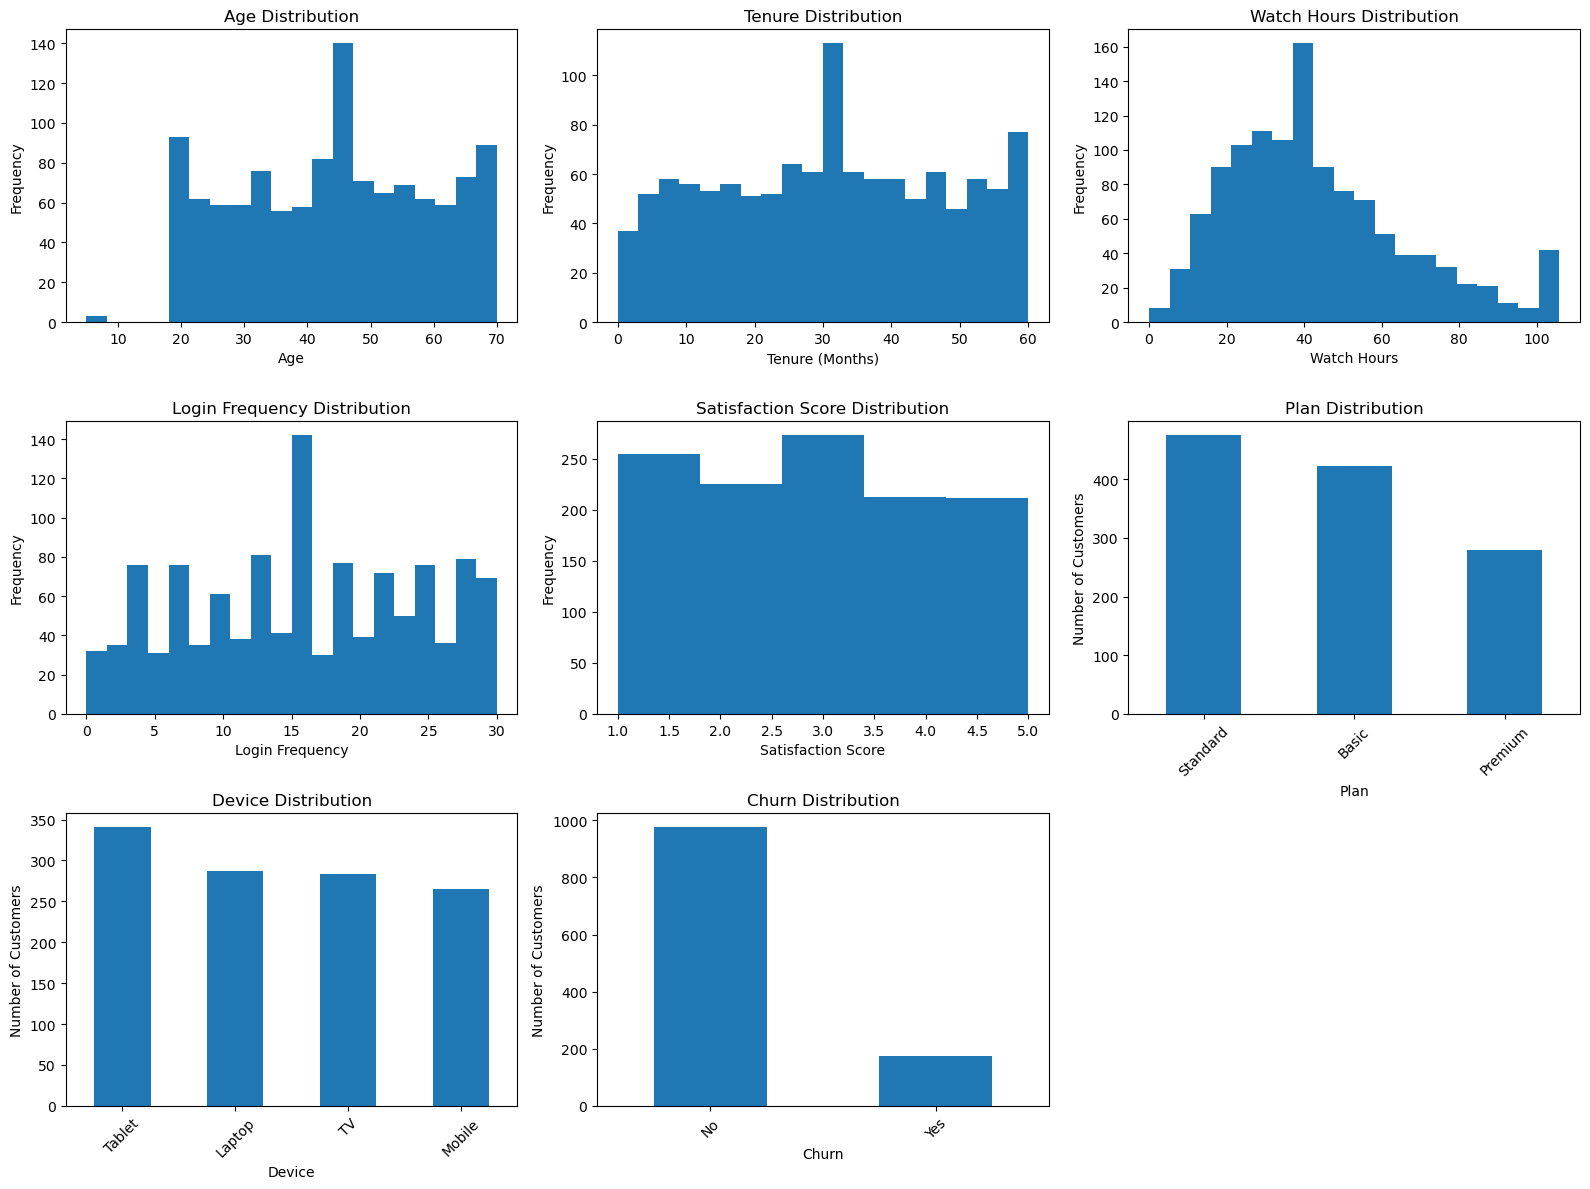

In [341]:


plt.figure(figsize=(16, 12))

# 1. Age
plt.subplot(3, 3, 1)
plt.hist(df["Age"], bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

# 2. Tenure_Months
plt.subplot(3, 3, 2)
plt.hist(df["Tenure_Months"], bins=20)
plt.title("Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Frequency")

# 3. Watch_Hours
plt.subplot(3, 3, 3)
plt.hist(df["Watch_Hours"], bins=20)
plt.title("Watch Hours Distribution")
plt.xlabel("Watch Hours")
plt.ylabel("Frequency")

# 4. Login_Frequency
plt.subplot(3, 3, 4)
plt.hist(df["Login_Frequency"], bins=20)
plt.title("Login Frequency Distribution")
plt.xlabel("Login Frequency")
plt.ylabel("Frequency")

# 5. Satisfaction_Score
plt.subplot(3, 3, 5)
plt.hist(df["Satisfaction_Score"], bins=5)
plt.title("Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Frequency")

# 6. Plan
plt.subplot(3, 3, 6)
df["Plan"].value_counts().plot(kind="bar")
plt.title("Plan Distribution")
plt.xlabel("Plan")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

# 7. Device
plt.subplot(3, 3, 7)
df["Device"].value_counts().plot(kind="bar")
plt.title("Device Distribution")
plt.xlabel("Device")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

# 8. Churn
plt.subplot(3, 3, 8)
df["Churn"].value_counts().plot(kind="bar")
plt.title("Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Bivariate Analysis

### 1. Satisfaction_Score vs Churn

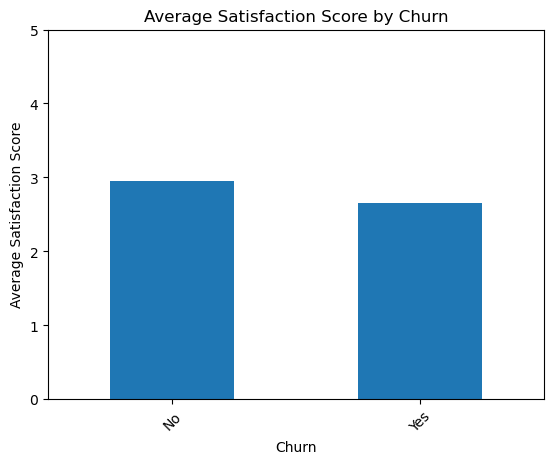

In [342]:
df.groupby("Churn")["Satisfaction_Score"].mean().plot(kind="bar")

plt.title("Average Satisfaction Score by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=45)
plt.ylim(0, 5)
plt.show()

### Insights
- Customers with lower satisfaction are more likely to churn.
- Customers with higher satisfaction are more likely to stay.
- This shows that customer satisfaction is related to churn.

### 2. Plan vs Churn

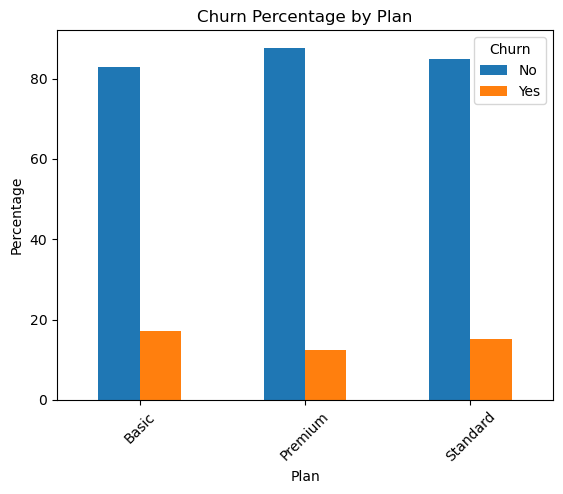

In [343]:
churn_plan = pd.crosstab(df["Plan"], df["Churn"], normalize="index") * 100

churn_plan.plot(kind="bar")

plt.title("Churn Percentage by Plan")
plt.xlabel("Plan")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.show()

### Insights
- Churn percentage is different for different plans.
- One plan may have higher churn than the others.
- This shows that subscription plan is related to customer churn.

### 3. Watch Hours vs Churn

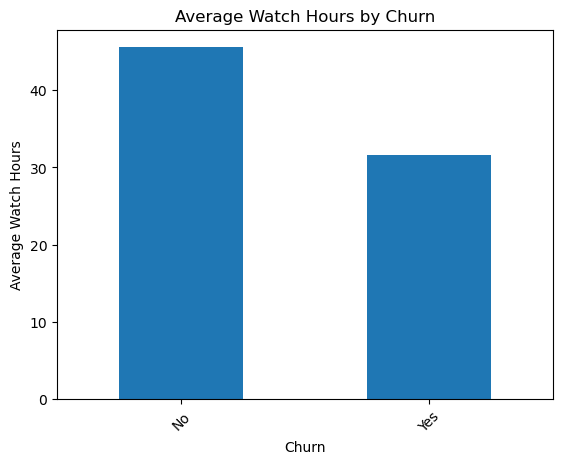

In [344]:
df.groupby("Churn")["Watch_Hours"].mean().plot(kind="bar")

plt.title("Average Watch Hours by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Watch Hours")
plt.xticks(rotation=45)
plt.show()

### Insights
- Customers who watch more hours generally show higher engagement.
- Customers with lower watch hours may be more likely to churn.
- This shows that watching activity is related to churn.

### 4. Login_Frequency vs Churn

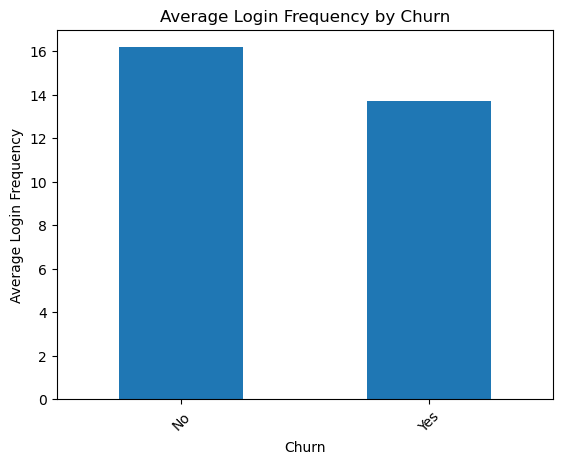

In [345]:
df.groupby("Churn")["Login_Frequency"].mean().plot(kind="bar")

plt.title("Average Login Frequency by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Login Frequency")
plt.xticks(rotation=45)
plt.show()

### Insights
- Customers who log in more frequently are more engaged.
- Customers with fewer logins may be more likely to churn.
- This shows that login frequency is related to churn.

## Coreelation Heatmap

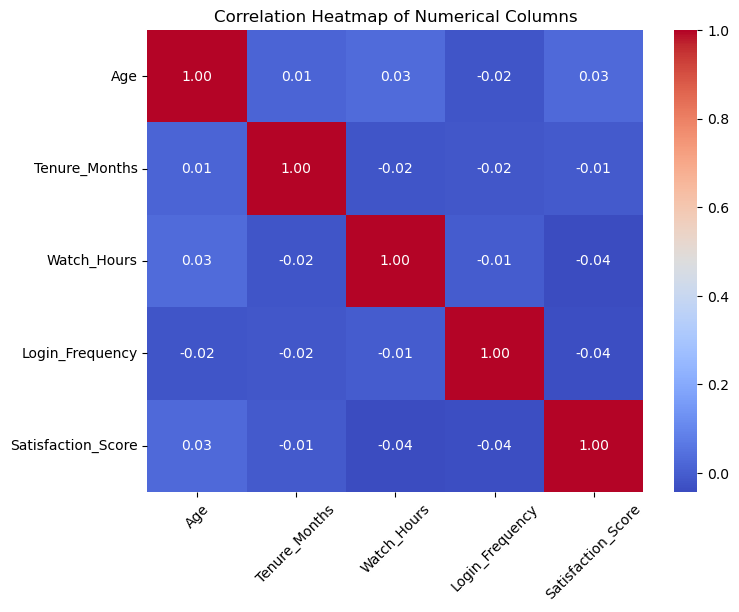

In [346]:
corr = df[[
    "Age",
    "Tenure_Months",
    "Watch_Hours",
    "Login_Frequency",
    "Satisfaction_Score"
]].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Columns")
plt.xticks(rotation=45)
plt.show()

- Blue -> negative correlation
- Light/neutral -> correlation around 0
- Red -> positive correlation

# Multivariate Analysis

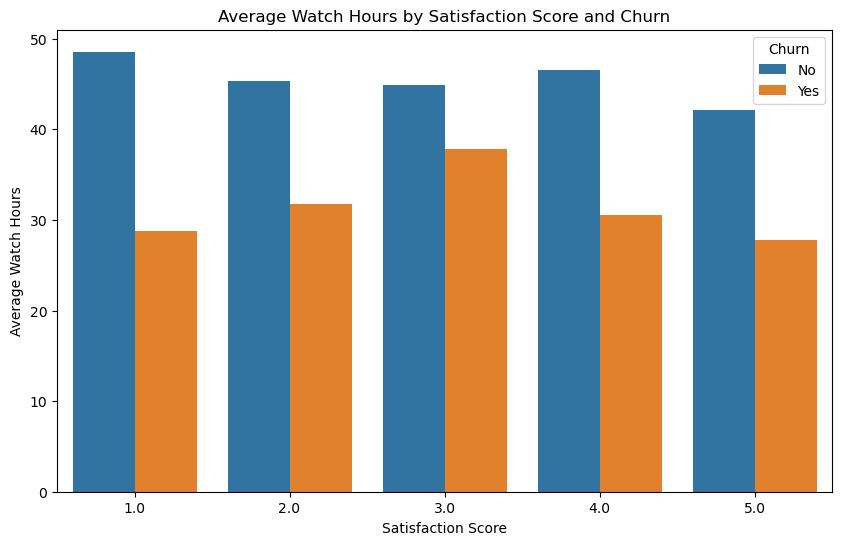

In [347]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Satisfaction_Score",
    y="Watch_Hours",
    hue="Churn",
    errorbar=None
)

plt.title("Average Watch Hours by Satisfaction Score and Churn")
plt.xlabel("Satisfaction Score")
plt.ylabel("Average Watch Hours")
plt.legend(title= "Churn" )
plt.show()

# Insights

- Churned customers may have lower average watch hours than retained customers.
- Customer satisfaction may be associated with differences in viewing behaviour.
- Comparing churn groups across satisfaction scores can reveal potential high-risk customer segments.